In [1]:
!pip install shap

In [2]:
import os
import kagglehub
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import shap

from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet169
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications.densenet import preprocess_input

In [3]:
DATASET_PATH = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Path to dataset files:", DATASET_PATH)

base_dir = os.path.join(DATASET_PATH, 'chest_xray', 'chest_xray')
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [4]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

print("\nCarregando conjunto de Treino (com validação dividida):")
train_dataset = tf.keras.utils.image_dataset_from_directory(train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, label_mode='binary', subset='training', validation_split=0.2, seed=42,shuffle=True)

validation_dataset = tf.keras.utils.image_dataset_from_directory(train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, label_mode='binary', subset='validation', validation_split=0.2, seed=42, shuffle=False)

print("\nCarregando conjunto de Teste:")
test_dataset = tf.keras.utils.image_dataset_from_directory(test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, label_mode='binary', shuffle=False)

class_names = train_dataset.class_names
print(f"\nClasses identificadas: {class_names}")


Carregando conjunto de Treino (com validação dividida):
Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.

Carregando conjunto de Teste:
Found 624 files belonging to 2 classes.

Classes identificadas: ['NORMAL', 'PNEUMONIA']


In [5]:
def normalize(image, label):
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

train_dataset = train_dataset.map(normalize)
validation_dataset = validation_dataset.map(normalize)
test_dataset = test_dataset.map(normalize)
print("Dados normalizados com sucesso!")

Dados normalizados com sucesso!


In [6]:
base_model = DenseNet169(weights='imagenet', include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [7]:
for layer in base_model.layers:
    layer.trainable = False

inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))

x = layers.RandomTranslation(height_factor=0.05, width_factor=0.05)(inputs)
x = layers.RandomZoom(height_factor=(-0.05, 0.05))(x)
x = layers.RandomRotation(factor=0.02)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='avg_pool')(x)
x = layers.Dense(256, activation='relu', name='fc_custom')(x)
x = layers.Dropout(0.5, name='dropout_custom')(x)
outputs = layers.Dense(1, activation='sigmoid', name='predictions')(x)

model = models.Model(inputs, outputs, name='densenet169_pneumonia')
model.summary()

Model: "densenet169_pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool                        │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_custom (Dense)               │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_custom (Dropout)        │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,069,377 (49.86 MB)

 Trainable params: 426,497 (1.63 MB)

 Non-trainable params: 12,642,880 (48.23 MB)

In [8]:
y_train_labels = []
for images, labels in train_dataset:
    y_train_labels.extend(labels.numpy().flatten())
y_train_labels = np.array(y_train_labels)

class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_labels), y=y_train_labels)

class_weights_dict = dict(enumerate(class_weights))
print("\nPesos das classes calculados:", class_weights_dict)


Pesos das classes calculados: {0: np.float64(1.9107142857142858), 1: np.float64(0.6772151898734177)}


In [9]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss=tf.keras.losses.BinaryCrossentropy(), metrics=['accuracy'])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

checkpoint_filepath = 'best_densenet169_pneumonia.weights.h5'
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_filepath, save_weights_only=True, monitor='val_accuracy', mode='max', save_best_only=True)

In [10]:
history = model.fit(train_dataset, epochs=12, validation_data=validation_dataset, class_weight=class_weights_dict,callbacks=[early_stopping, model_checkpoint_callback])

Epoch 1/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 73s 388ms/step - accuracy: 0.8248 - loss: 0.3728 - val_accuracy: 0.9406 - val_loss: 0.1548
Epoch 2/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 311ms/step - accuracy: 0.9260 - loss: 0.1925 - val_accuracy: 0.9492 - val_loss: 0.1317
Epoch 3/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 39s 299ms/step - accuracy: 0.9389 - loss: 0.1643 - val_accuracy: 0.9444 - val_loss: 0.1492
Epoch 4/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 300ms/step - accuracy: 0.9458 - loss: 0.1471 - val_accuracy: 0.9338 - val_loss: 0.1760
Epoch 5/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 299ms/step - accuracy: 0.9470 - loss: 0.1315 - val_accuracy: 0.9329 - val_loss: 0.1729
Epoch 6/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 314ms/step - accuracy: 0.9514 - loss: 0.1258 - val_accuracy: 0.9511 - val_loss: 0.1314
Epoch 7/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 44s 334ms/step - accuracy: 0.9595 - loss: 0.1151 - val_accuracy: 0.9511 - val_loss: 0.1342
Epoch 8/12
131/131 ━━━━━━━━━━━━━━━━━━━━ 39s 298ms/step - accuracy: 0.9557 - loss: 0

In [11]:
model.load_weights(checkpoint_filepath)

MODEL_PATH = 'densenet169_pneumonia.keras'
model.save(MODEL_PATH)
print(f"\nModelo salvo em: {MODEL_PATH}")

loss, accuracy = model.evaluate(test_dataset, verbose=2)
print(f"Acurácia do modelo no conjunto de teste: {accuracy:.4f}")


Modelo salvo em: densenet169_pneumonia.keras
20/20 - 6s - 316ms/step - accuracy: 0.8830 - loss: 0.3118
Acurácia do modelo no conjunto de teste: 0.8830


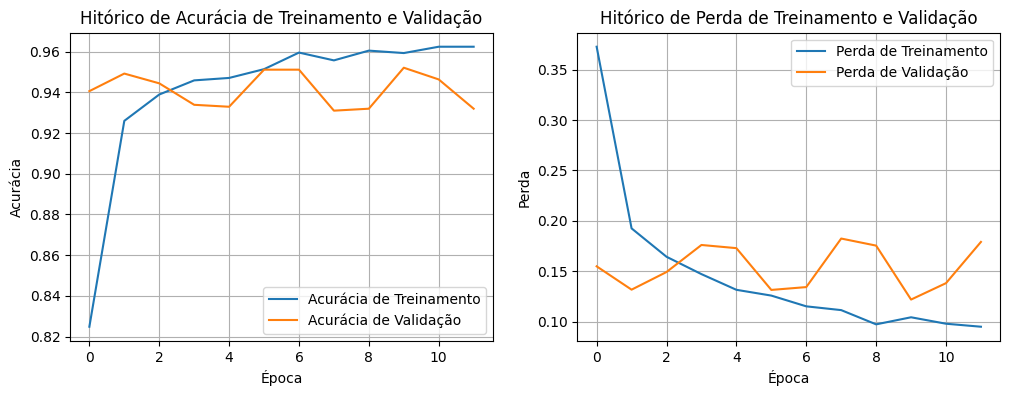

In [12]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Acurácia de Treinamento')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.title('Hitórico de Acurácia de Treinamento e Validação')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perda de Treinamento')
plt.plot(history.history['val_loss'], label='Perda de Validação')
plt.xlabel('Época')
plt.ylabel('Perda')
plt.title('Hitórico de Perda de Treinamento e Validação')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
y_pred_prob = model.predict(test_dataset)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = np.concatenate([y.numpy() for x, y in test_dataset], axis=0).flatten()

relatorio = classification_report(y_true, y_pred, target_names=class_names)
print("Relatório de Classificação:\n")
print(relatorio)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 419ms/step
Relatório de Classificação:

              precision    recall  f1-score   support

      NORMAL       0.92      0.75      0.83       234
   PNEUMONIA       0.87      0.96      0.91       390

    accuracy                           0.88       624
   macro avg       0.89      0.86      0.87       624
weighted avg       0.89      0.88      0.88       624



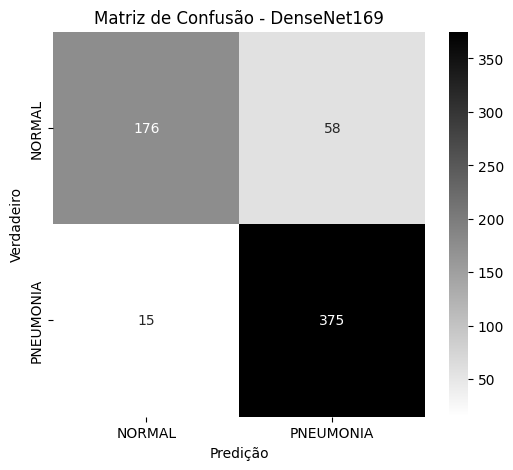

In [14]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='gray_r',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predição')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão - DenseNet169')
plt.savefig('confusion_matrix.png', bbox_inches='tight', dpi=300)
plt.show()

In [15]:
for images, labels in train_dataset.take(1):
    background = images[:20].numpy()
    test_sample = images[:5].numpy()
    real_classes = labels[:5].numpy().astype(int).flatten()

pred = model.predict(test_sample)
pred_classes = (pred >= 0.5).astype(int).flatten()

print("Classes Preditas:", pred_classes)
print("Classes Reais:   ", real_classes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Classes Preditas: [1 1 0 0 1]
Classes Reais:    [1 1 0 0 1]


In [16]:
explainer = shap.GradientExplainer(model, background)
shap_values = explainer.shap_values(test_sample)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_595
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_595
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)



Classe prevista: PNEUMONIA | Classe real: PNEUMONIA


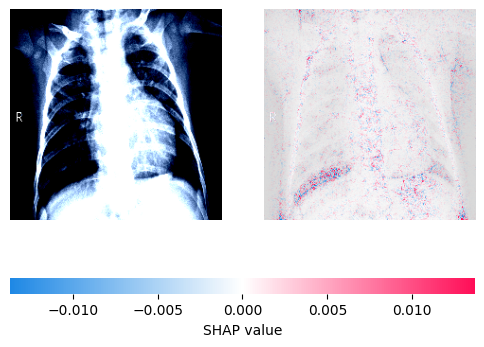


Classe prevista: PNEUMONIA | Classe real: PNEUMONIA


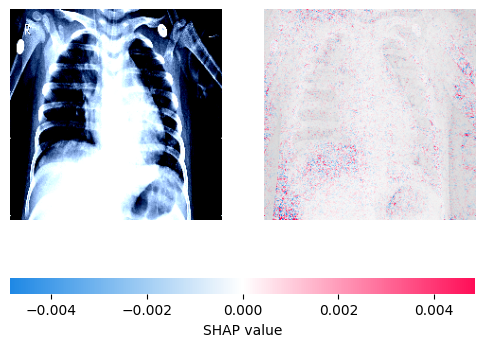


Classe prevista: NORMAL | Classe real: NORMAL


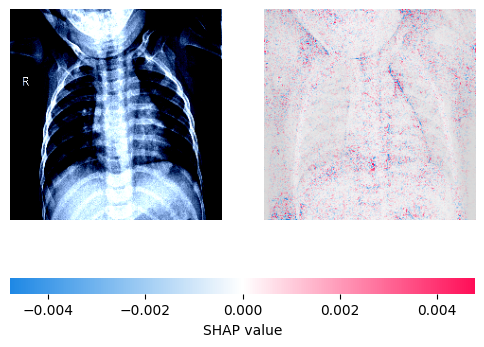


Classe prevista: NORMAL | Classe real: NORMAL


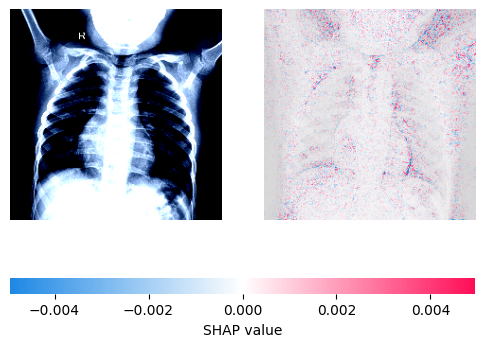


Classe prevista: PNEUMONIA | Classe real: PNEUMONIA


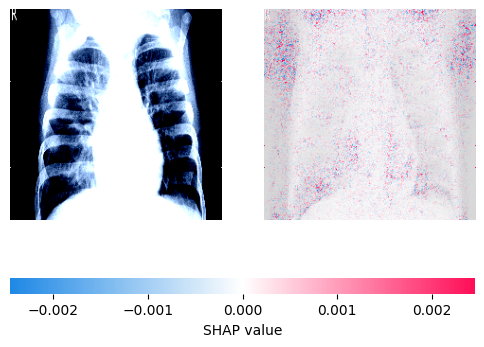

In [17]:
for i in range(len(test_sample)):
    print(f"\nClasse prevista: {class_names[pred_classes[i]]} | Classe real: {class_names[real_classes[i]]}")
    current_shap = shap_values[i, :, :, :, 0]
    current_img = test_sample[i, :, :, :]
    shap.image_plot(current_shap, current_img)